# ScAn: Bayesian Optimization Aimed at the Target Compute

The [ScaleFM demo](scalefm_demo.ipynb) acquired runs with Chinchilla's
approach 1 and random search, and extrapolated them to a target compute. **ScAn**
spends the same budget more deliberately: it tunes the model size and data together
with the other training hyperparameters, and picks the runs that tell it most about
the best loss at the target compute.

<p align="center"><img src="static/scan_loss_over_cost.png" width="420"><br><b>ScAn</b>: the Gaussian process of its runs, extrapolated to the target</p>

It runs on the same TabPFN surrogate benchmark, pipeline and search space as the
demo.

## Installation
Requires Python 3.11+. In Colab, run the cell below; locally, see the
[README](README.md).

In [ ]:
!git clone --depth 1 https://github.com/automl/scalefm.git /content/scalefm_repo
%cd /content/scalefm_repo/tutorials
!pip install -e "/content/scalefm_repo[carbs]"
# Surrogate benchmark of TabPFN, it makes every run take a fraction of a second
!pip install scan-bench

In [1]:
import logging
import os

# The surrogates run in forked worker processes later on, which needs a single
# OpenMP thread (set before they load)
os.environ["OMP_NUM_THREADS"] = "1"
import warnings
from pathlib import Path

from IPython.display import Image, display
from scan_bench import TabPFNTarget

import scalefm
import tabpfn_scan_bench as tabpfn

logging.basicConfig(level=logging.WARNING)
logging.getLogger("scalefm").setLevel(logging.INFO)
warnings.filterwarnings("ignore")


def show(*images, width=480):
    """Show PNG files, e.g. the plots of a run's `summary/`."""
    for image in images:
        display(Image(filename=image, width=width))

/home/alipourn/scalefm/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The pipeline

`evaluate_pipeline` is the function `scalefm.acquire` calls with every config. It
trains a model and returns what the scaling analysis needs: the loss to minimize, the
training cost, the model size and data, and optionally downstream performances and
the inference cost.

Here, the surrogate benchmark of `scan_bench` stands in for the training: it predicts
what a TabPFN training run would reach, its validation loss and its negative
log-likelihood on real tabular datasets, a **downstream** metric.

In [2]:
loss_benchmark = tabpfn.get_benchmark(TabPFNTarget.VAL_LOSS)
nll_benchmark = tabpfn.get_benchmark(TabPFNTarget.NLL)  # Fitted on first use, ~20s


def evaluate_pipeline(**config) -> dict:
    """Train TabPFN with `config`, here: ask the surrogates what it would reach."""
    run = tabpfn.build_config(**config)
    flops_per_cell = tabpfn.flops_estimator(**{**config, "total_cells": 1})
    return {
        "objective_to_minimize": loss_benchmark.query(run)["predictions"]["mean"],
        "cost": flops_per_cell * run.total_cells,  # Training FLOPs
        "inference_cost": flops_per_cell / 3,  # FLOPs of a forward pass over one cell
        "n_params": tabpfn.parameters_estimator(**config),
        "n_data": run.total_cells,
        "downstream_performances": {
            "real_nll": nll_benchmark.query(run)["predictions"]["mean"]
        },
    }

## The search space

The search space is the most important design decision in a study. It defines every
parameter of a run: its type, its scale (log, linear, ...), its range and its
constraints. If it is badly defined, no optimizer can make up for it. Mark the
parameters that drive compute cost with `is_compute_scaling=True`: the scaling
optimizers lay out their runs along these axes.

The model size is determined by `embedding_size` and `num_layers`, the amount of data by
`total_cells`.

In [3]:
class TabPFNSpace(scalefm.PipelineSpace):
    # Compute-scaling parameters: the model size and the data
    total_cells = scalefm.Integer(2**20, 2**35, log=True, log_base=2, is_compute_scaling=True)
    embedding_size = scalefm.Integer(4, 256, log=True, log_base=2, is_compute_scaling=True)
    num_layers = scalefm.Integer(2, 32, log=True, log_base=2, is_compute_scaling=True)
    # The other hyperparameters
    effective_batch_size = scalefm.Integer(16, 256, log=True, log_base=2)
    lr = scalefm.Float(1e-4, 5e-2, log=True)

Every acquisition gets the same FLOP budget, at most a tenth of it per run, and we
predict at a target 20x the cost of the largest run.

In [4]:
RESULTS = Path("results/scaling_tutorial")

MAX_COST_PER_RUN = 2.8e14
BUDGET = MAX_COST_PER_RUN * 10
TARGET = 5.6e15
TARGETS = [TARGET]

## Acquisition with ScAn

ScAn is Bayesian optimization with scaling-specific parts: an information-theoretic
acquisition aimed at `target_cost`, and a power-law prior mean. Unlike a static
layout such as Chinchilla's, it fits a model to the runs before choosing the next
one, which takes time, and needs earlier results to choose well, so by default it runs
one run after the other. It also runs on parallel workers, as in section 5 of the
demo, with the same `optimizer`.

In [5]:
SCAN = RESULTS / "scan"
SCAN_OPTIMIZER = (
    "bayesian_optimization",
    {
        "acquisition_func_type": "IT-SCAN-JES",
        "target_cost": TARGET,
        "prior_mean": "power_law",
        "budget_schedule": "left_budget_contraction",
    },
)

tabpfn.set_seed(0)
scalefm.acquire(
    evaluate_pipeline=evaluate_pipeline,
    pipeline_space=TabPFNSpace(),
    root_directory=SCAN,
    optimizer=SCAN_OPTIMIZER,
    cost_estimator=tabpfn.flops_estimator,
    max_cost_per_config=MAX_COST_PER_RUN,
    total_cost_to_spend=BUDGET,
    overwrite_root_directory=True,
)

full, _ = scalefm.status(SCAN)
print(f"{len(full)} runs, {full['cost'].sum():.2e} FLOPs,"
      f" best loss {full['objective_to_minimize'].min():.3f}")

INFO:scalefm.api:Starting scalefm.acquire using root directory results/scaling_tutorial/scan


INFO:scalefm.api:SearchSpace(elements={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOFloat(lower=0.0001, upper=0.05, center=0.002236067977499791, log=True, log_base=None, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'num_layers': HPOInteger(lower=2, upper=32, center=8, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, categoricals={}, numerical={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log_ba

INFO:scalefm.runtime:Overwriting optimization directory 'results/scaling_tutorial/scan' as `overwrite_optimization_dir=True`.


INFO:scalefm.runtime:Summary files can be found in the “summary” folder inside the root directory: /home/alipourn/scalefm/tutorials/results/scaling_tutorial/scan/summary


INFO:scalefm.runtime:Using optimizer: bayesian_optimization


INFO:scalefm.optimizers.bayesian_optimization:Budget schedule 'left_budget_contraction': max cost 5.600000e+13 per config, spent 0.000000e+00 of 2.800000e+15.


... (174 outputs left out)

INFO:scalefm.runtime:Worker 'worker_0' evaluated trial: 30 as success.


INFO:scalefm.runtime:Worker 'worker_0' stops: Only 4.282413e+13 of the cost budget 2.800000e+15 is left, less than the 5.600000e+13 of the cheapest config the schedule samples.


INFO:scalefm.api:The summary folder has been created, with full.csv (all runs) and the plots.
You can find summary folder at: results/scaling_tutorial/scan/summary.


31 runs, 2.76e+15 FLOPs, best loss 0.930


## Prediction with `gp_posterior`

ScAn's own predictor, `gp_posterior`, which `predictor="auto"` picks, fits the same
Gaussian process the optimizer used to all the runs. It needs the estimators to turn
a predicted config into its model size and cost:

C=5.6e+15: loss 0.792, N*=1.94e+04, D*=4.81e+10
config: {'effective_batch_size': 16, 'embedding_size': 16, 'lr': 0.0004332317890028154, 'num_layers': 4, 'total_cells': 34359738368}


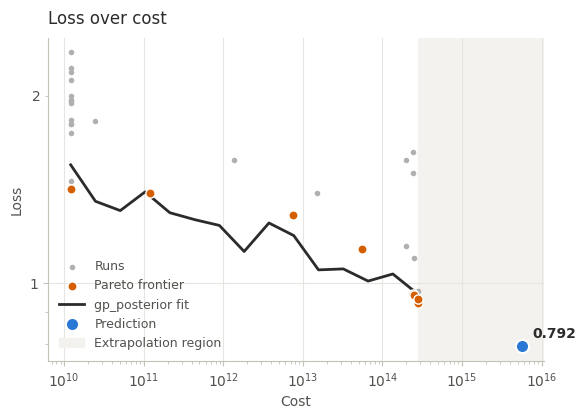

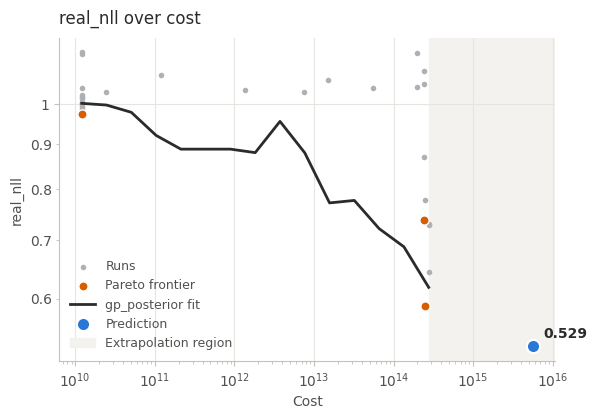

In [6]:
(prediction,) = scalefm.predict(
    SCAN, target_costs=TARGETS,
    params_estimator=tabpfn.parameters_estimator, cost_estimator=tabpfn.flops_estimator,
    cache_dir=SCAN / "gp_cache",
)
print(f"C={TARGET:.1e}: loss {prediction.loss:.3f},"
      f" N*={prediction.n_params:.2e}, D*={prediction.n_data:.2e}")
print("config:", prediction.config)
show(SCAN / "summary/pre_train/loss_over_cost.png",
     SCAN / "summary/downstream/real_nll/real_nll_over_cost.png")

ScAn tunes every hyperparameter, and the Gaussian process predicts all of them, so
each has a fit and a prediction at the target:

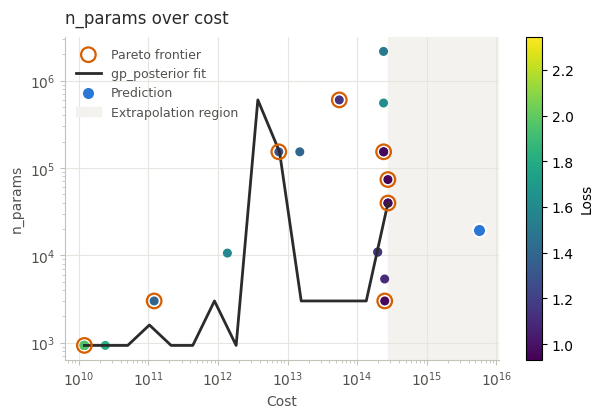

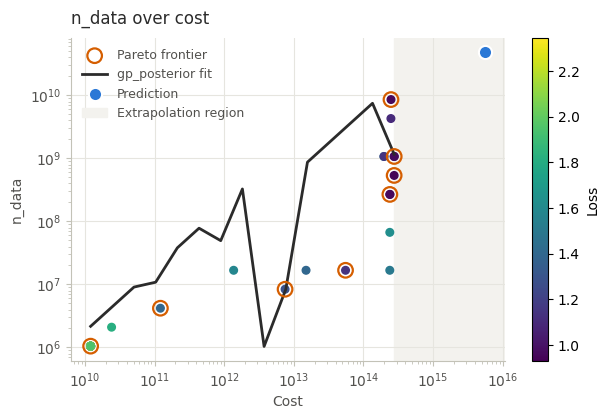

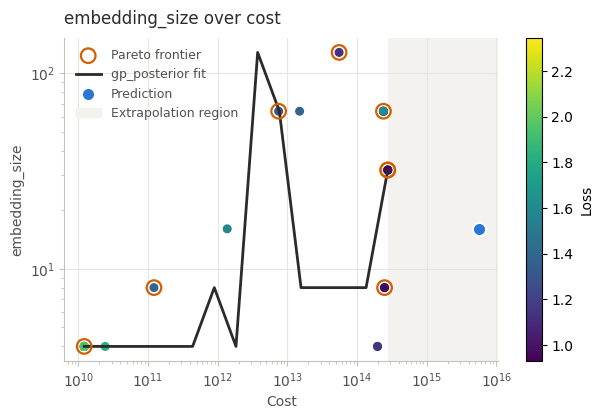

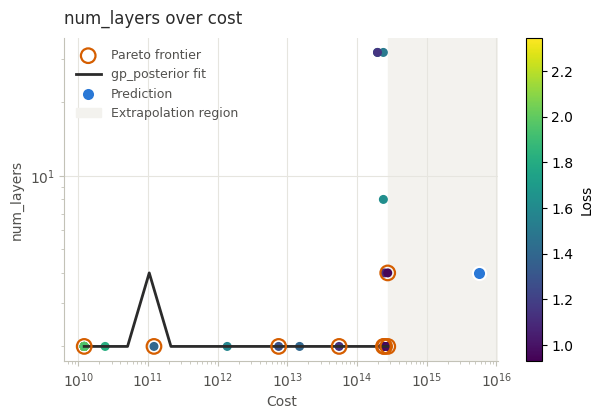

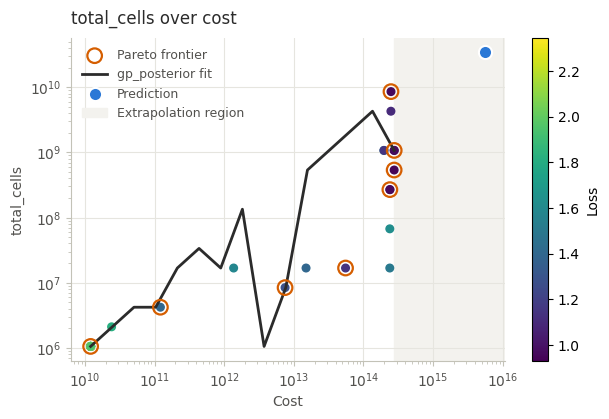

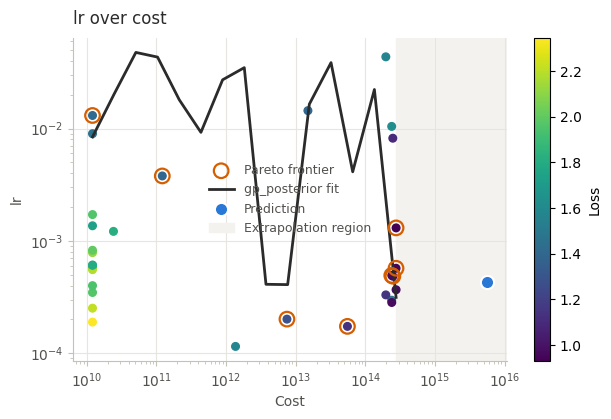

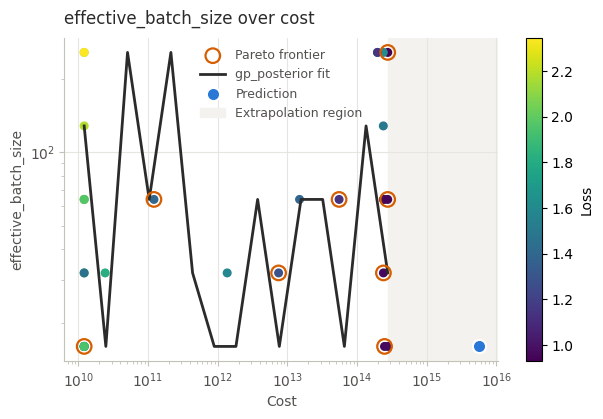

In [7]:
show(*[SCAN / f"summary/pre_train/parameters/{name}_over_cost.png"
       for name in ["n_params", "n_data", "embedding_size", "num_layers", "total_cells",
                    "lr", "effective_batch_size"]],
     width=420)

And the predicted config at the target:

In [8]:
print((SCAN / "summary/pre_train/predictions_over_cost.txt").read_text())

 target_cost   loss  n_params    n_data  effective_batch_size  embedding_size        lr  num_layers  total_cells
     5.6e+15 0.7921  1.94e+04 4.811e+10                    16              16 0.0004332           4  34359738368



## Chinchilla approach 1, for comparison

The same budget spent by Chinchilla's approach 1, as in the demo, on the space with a
fixed training recipe. `chinchilla3` predicts the loss, but no config, so we predict
the config from the same runs with `power_law`:

In [9]:
RECIPE = dict(num_layers=2, effective_batch_size=64, lr=1e-3)


class TabPFNChinchillaSpace(scalefm.PipelineSpace):
    total_cells = scalefm.Integer(2**20, 2**35, log=True, log_base=2, is_compute_scaling=True)
    embedding_size = scalefm.Integer(4, 256, log=True, log_base=2, is_compute_scaling=True)
    # The fixed recipe
    num_layers = RECIPE["num_layers"]
    effective_batch_size = RECIPE["effective_batch_size"]
    lr = RECIPE["lr"]


CHINCHILLA1 = RESULTS / "chinchilla1"

tabpfn.set_seed(0)
scalefm.acquire(
    evaluate_pipeline=evaluate_pipeline,
    pipeline_space=TabPFNChinchillaSpace(),
    root_directory=CHINCHILLA1,
    optimizer=(
        "chinchilla",
        {
            "strategy": "approach1",
            "data_parameter_name": "total_cells",
            "params_estimator": tabpfn.parameters_estimator,
            "data_multipliers": [300, 1e3, 3e3, 1e4],
        },
    ),
    cost_estimator=tabpfn.flops_estimator,
    total_cost_to_spend=BUDGET,
    overwrite_root_directory=True,
)

(chinchilla_loss,) = scalefm.predict(CHINCHILLA1, target_costs=TARGETS)
(chinchilla_full,) = scalefm.predict(CHINCHILLA1, target_costs=TARGETS, predictor="power_law")
print(f"C={TARGET:.1e}: loss {chinchilla_loss.loss:.3f}")
print("config:", chinchilla_full.config)

INFO:scalefm.api:Starting scalefm.acquire using root directory results/scaling_tutorial/chinchilla1


INFO:scalefm.api:SearchSpace(elements={'effective_batch_size': HPOConstant(value=64), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOConstant(value=0.001), 'num_layers': HPOConstant(value=2), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, categoricals={}, numerical={'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, fidelities={}, constants={'effective_batch_size': 64, 'lr': 0.001, 'num_layers': 2})


INFO:scalefm.runtime:Overwriting optimization directory 'results/scaling_tutorial/chinchilla1' as `overwrite_optimization_dir=True`.


INFO:scalefm.runtime:Summary files can be found in the “summary” folder inside the root directory: /home/alipourn/scalefm/tutorials/results/scaling_tutorial/chinchilla1/summary


INFO:scalefm.runtime:Using optimizer: chinchilla


INFO:scalefm.optimizers.chinchilla:grid for model params {'embedding_size': [4, 8, 16, 32, 64, 128, 256]}


... (118 outputs left out)

INFO:scalefm.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.665000, A=4.006842e-01, B=1.187027e+01, alpha=0.2500, beta=0.2500


INFO:scalefm.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.277272, A=1.763443e-04, B=5.681184e+01, alpha=0.2500, beta=0.2500


INFO:scalefm.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.277272, A=1.763443e-04, B=5.681184e+01, alpha=0.2500, beta=0.2500


C=5.6e+15: loss 0.903
config: {'embedding_size': 128, 'total_cells': 4294967296}


## Does the prediction hold?

On the benchmark we can check a prediction: train the predicted config and compare its
loss with the predicted one. The reference is the surrogate's own best config at the
target, which `tabpfn.reference_optimum` finds by searching the benchmark directly.

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

reference = tabpfn.reference_optimum(TARGET)
quality = []


def check(acquisition, predicted_loss, config):
    """Train the predicted `config` and keep its loss next to the predicted one."""
    result = evaluate_pipeline(**config)
    quality.append({
        "acquisition": acquisition,
        "config FLOPs": f"{result['cost']:.2e}",
        "predicted loss": round(predicted_loss, 3),
        "evaluated loss": round(result["objective_to_minimize"], 3),
        "reference loss": round(reference.loss, 3),
        **{name: config[name] for name in
           ["embedding_size", "num_layers", "total_cells", "lr", "effective_batch_size"]},
    })
    return pd.DataFrame(quality).set_index("acquisition")


def plot_quality():
    """The predicted and evaluated loss of each predicted config, against the reference."""
    table = pd.DataFrame(quality)
    x = range(len(table))
    fig, ax = plt.subplots(figsize=(max(6.4, 2 * len(table) + 1), 4.4))
    ax.vlines(x, table["predicted loss"], table["evaluated loss"], color="#B0B0B0",
              linewidth=2, zorder=1)
    ax.scatter(x, table["predicted loss"], s=90, facecolors="white", edgecolors="#2B2B2B",
               linewidths=2, zorder=3, label="predicted")
    ax.scatter(x, table["evaluated loss"], s=90, color="#2B2B2B", zorder=3,
               label="evaluated")
    ax.axhline(reference.loss, color="#D55E00", linestyle="--", linewidth=1.5,
               label="reference")
    for i, row in table.iterrows():
        for column, color in [("evaluated loss", "#2B2B2B"), ("predicted loss", "#52514E")]:
            ax.annotate(f"{row[column]:.3f}", (i, row[column]), textcoords="offset points",
                        xytext=(10, -4), color=color)
    ax.set_xticks(list(x), table["acquisition"])
    ax.set_xlim(-0.6, len(table) - 0.4)
    ax.set(ylabel="validation loss", title=f"Loss of the predicted config at {TARGET:.1e} FLOPs")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#E6E5DF")
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3,
              fontsize=9)
    plt.tight_layout()
    plt.show()


check("Chinchilla", chinchilla_loss.loss, {**RECIPE, **chinchilla_full.config})
check("ScAn", prediction.loss, prediction.config)

,config FLOPs,predicted loss,evaluated loss,reference loss,embedding_size,num_layers,total_cells,lr,effective_batch_size
acquisition,,,,,,,,,
Chinchilla,1.42e+16,0.903,1.035,0.834,128,2,4294967296,0.001000,64
ScAn,5.59e+15,0.792,0.886,0.834,16,4,34359738368,0.000433,16


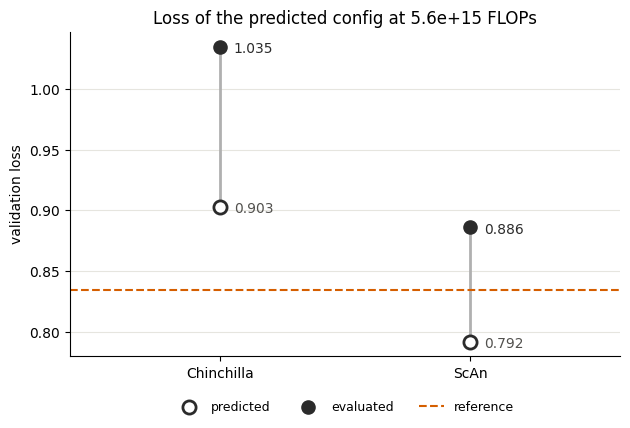

In [11]:
plot_quality()